In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, average_precision_score, roc_auc_score, confusion_matrix, precision_recall_curve

from src import data_prep   # cleaning, split and preprocessor live in src/data_prep.py

df = data_prep.load_raw("bank-additional-full.csv")
df.shape
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [2]:
n0 = len(df)
df["y"].value_counts(normalize=True)
df.isna().sum().sum()
(df == "unknown").sum()

age                  0
job                330
marital             80
education         1731
default           8597
housing            990
loan               990
contact              0
month                0
day_of_week          0
duration             0
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
y                    0
dtype: int64

In [3]:
df.duplicated().sum()
df["pdays"].eq(999).mean()

np.float64(0.9632174419733903)

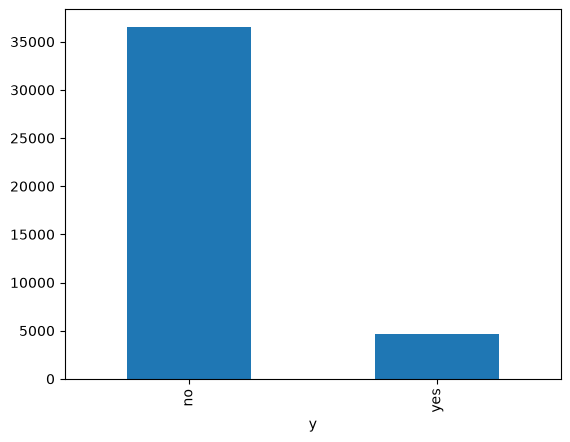

job
admin.           0.129726
blue-collar      0.068943
entrepreneur     0.085165
housemaid        0.100000
management       0.112175
retired          0.252326
self-employed    0.104856
services         0.081381
student          0.314286
technician       0.108260
unemployed       0.142012
unknown          0.112121
Name: y, dtype: float64

In [4]:
df.select_dtypes("number").corr()
df["y"].value_counts().plot.bar()
plt.show()
df.groupby("job")["y"].apply(lambda s: (s == "yes").mean())

In [5]:
df_clean = data_prep.clean(df)
df_clean.to_csv("bank_clean.csv", index=False)

In [6]:
# NOTE: a random split mixes early and late rows of this date-sorted file (no date column),
# so it hides date drift: val/test scores are likely optimistic vs a future campaign.
X_train, X_val, X_test, y_train, y_val, y_test = data_prep.split(df_clean)
print(len(X_train), len(X_val), len(X_test), y_train.mean(), y_val.mean(), y_test.mean())

24705 8235 8236 0.11264926128314107 0.11268973891924712 0.11267605633802817


In [7]:
# Module 2 assertions (run before the baseline cells)
from sklearn.utils.validation import check_is_fitted
from sklearn.exceptions import NotFittedError

# 1. split sizes
assert (len(X_train), len(X_val), len(X_test)) == (24705, 8235, 8236)

# 2. class share per split is close to the overall share
overall = df_clean["y"].mean()
for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    assert abs(part.mean() - overall) < 0.002, name

# 3. no index overlap between splits (index was never reset)
i_tr, i_val, i_te = set(X_train.index), set(X_val.index), set(X_test.index)
assert not (i_tr & i_val) and not (i_tr & i_te) and not (i_val & i_te)

# 4. column naming: pdays everywhere, no pdays_clean
for name, frame in [("df_clean", df_clean), ("X_train", X_train), ("X_val", X_val), ("X_test", X_test)]:
    assert "pdays" in frame.columns and "pdays_clean" not in frame.columns, name

# 5. preprocessor is unfitted before fit (fresh object, so the baseline's prep is not involved)
check_prep = data_prep.build_preprocessor()
try:
    check_is_fitted(check_prep)
    raise AssertionError("preprocessor is already fitted")
except NotFittedError:
    pass

# 6. scaler mean comes from train only (equals train mean, differs from full-data mean)
check_prep.fit(X_train)
scaler_mean = check_prep.named_transformers_["num"].mean_
train_mean = X_train[data_prep.NUMERIC_COLS].mean().values
full_mean = df_clean[data_prep.NUMERIC_COLS].mean().values
assert np.allclose(scaler_mean, train_mean, rtol=0, atol=1e-9)
assert not np.allclose(scaler_mean, full_mean, rtol=0, atol=1e-9)
print("all assertions passed")

all assertions passed


In [8]:
prep = data_prep.build_preprocessor()
majority = DummyClassifier(strategy="prior").fit(X_train, y_train)
logreg = Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=2000))]).fit(X_train, y_train)

In [9]:
p = logreg.predict_proba(X_val)[:, 1]
pred = (p >= 0.5).astype(int)
confusion_matrix(y_val, pred); precision_score(y_val, pred); recall_score(y_val, pred)
f1_score(y_val, pred); average_precision_score(y_val, p); roc_auc_score(y_val, p)
prec, rec, thr = precision_recall_curve(y_val, p)       # then pick the threshold with best F1
f1 = 2*prec[:-1]*rec[:-1]/(prec[:-1]+rec[:-1]); best = thr[f1.argmax()]

In [ ]:
# Week 3: chronological split (separate variable names, the random split above is untouched)
# Assumes row order = time order. No shuffling, no stratification.
Xt_train, Xt_val, Xt_test, yt_train, yt_val, yt_test = data_prep.time_split(df_clean)
print(len(Xt_train), len(Xt_val), len(Xt_test))

In [ ]:
# Time split assertions
# 1. sizes
assert (len(Xt_train), len(Xt_val), len(Xt_test)) == (24705, 8235, 8236)

# 2. original order kept, blocks strictly one after the other
assert df_clean.index.is_monotonic_increasing
assert Xt_train.index.max() < Xt_val.index.min()
assert Xt_val.index.max() < Xt_test.index.min()
for name, X_part, y_part in [("train", Xt_train, yt_train), ("val", Xt_val, yt_val), ("test", Xt_test, yt_test)]:
    assert X_part.index.is_monotonic_increasing, name
    assert X_part.index.equals(y_part.index), name   # X and y aligned

# 3. no overlap, nothing lost
t_tr, t_val, t_te = set(Xt_train.index), set(Xt_val.index), set(Xt_test.index)
assert not (t_tr & t_val) and not (t_tr & t_te) and not (t_val & t_te)
assert len(t_tr | t_val | t_te) == len(df_clean)

# 4. positive share per block: printed only, NOT asserted equal (no stratification)
for name, y_part in [("train", yt_train), ("val", yt_val), ("test", yt_test)]:
    print(f"{name}: n={len(y_part)}, positive share={y_part.mean():.4f}")
print("time split assertions passed")

In [ ]:
# Drift diagnostics: TRAIN vs VALIDATION only (the test block is not used here)
drift_cols = ["emp.var.rate", "euribor3m", "nr.employed", "cons.price.idx", "cons.conf.idx"]
rows = []
for col in drift_cols:
    lo, hi = Xt_train[col].min(), Xt_train[col].max()
    outside = ((Xt_val[col] < lo) | (Xt_val[col] > hi)).mean()   # share of val rows outside train range
    rows.append({"column": col, "train_min": lo, "train_max": hi, "val_share_outside": outside})
print(pd.DataFrame(rows).to_string(index=False))